# Return Distribution with VaR and CVaR

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

A histogram of periodic returns with a fitted normal curve and the historical Value-at-Risk (VaR) and Conditional VaR (CVaR, expected shortfall) marked. A second panel uses a log density scale so the fat left tail is visible. Real returns have more extreme days than a normal distribution predicts, and risk models that assume normality understate losses.

## When to use

- Explain tail risk and what VaR / CVaR actually measure
- Show that returns are fat-tailed or skewed compared with a normal model
- Compare the loss distribution of two strategies (overlay or small multiples)

## Avoid when

- Fewer than a few hundred observations (the tails are not estimable)
- The audience only needs a single risk number (use a stat tile with the VaR)

## Alternatives

- Q-Q plot against the normal distribution
- ECDF of returns with the 5% quantile marked
- Box plot of returns by year

## Design tips

- State the confidence level, horizon and method (historical, parametric, Monte Carlo)
- Report VaR as a positive loss or a negative return, but be consistent
- Use a log y-axis or a tail zoom to make rare events visible

## Example

10 years of simulated daily returns drawn from a Student-t distribution (5 degrees of freedom), so the tails are fatter than normal. Historical 95% and 99% one-day VaR and 95% CVaR. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy import stats
from matplotlib.ticker import PercentFormatter

### Data

In [2]:
rng = np.random.default_rng(8)
r = pd.Series(0.0004 + rng.standard_t(5, 2520) * 0.01 * np.sqrt(3 / 5), name="Fund daily returns")
horizon = "one-day"
r.describe()

count    2520.000000
mean        0.000139
std         0.010487
min        -0.133075
25%        -0.005546
50%         0.000161
75%         0.006139
max         0.072329
Name: Fund daily returns, dtype: float64

### Plot

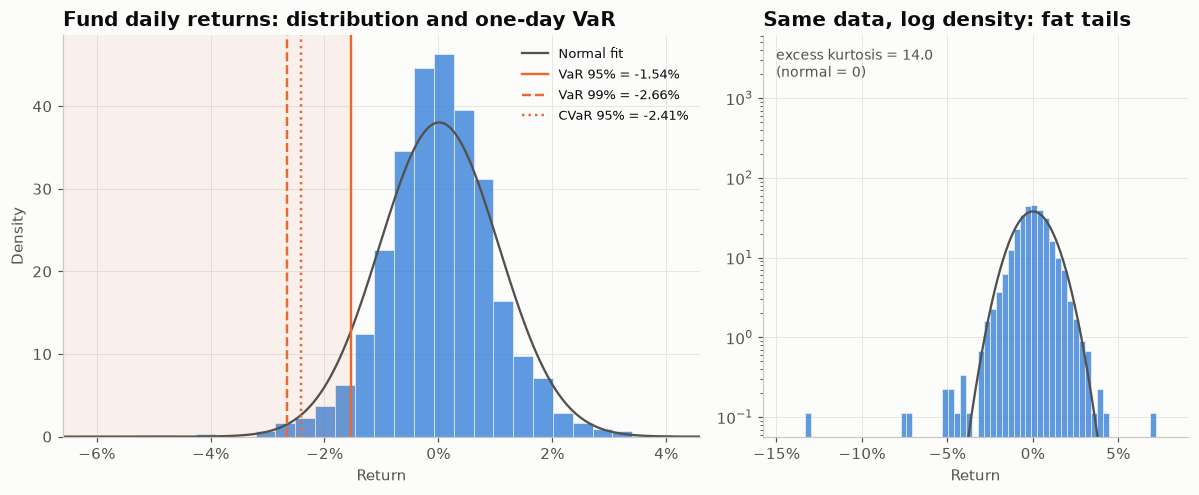

In [3]:
var95, var99 = np.quantile(r, [0.05, 0.01])
cvar95 = r[r <= var95].mean()
mu, sd = r.mean(), r.std()
xs = np.linspace(r.min() * 1.1, r.max() * 1.1, 400)
bins = np.linspace(r.min(), r.max(), 60 if len(r) > 500 else 25)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
for a in (ax, ax2):
    a.hist(r, bins=bins, density=True, color=PALETTE[0], alpha=0.75, edgecolor="#fcfcfb", linewidth=0.5)
    a.plot(xs, stats.norm.pdf(xs, mu, sd), color="#52514e", linewidth=1.5, label="Normal fit")
    a.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0 if r.abs().max() > 0.1 else 1))
for v, lab, style in [(var95, f"VaR 95% = {var95:.2%}", "-"), (var99, f"VaR 99% = {var99:.2%}", "--"),
                      (cvar95, f"CVaR 95% = {cvar95:.2%}", ":")]:
    ax.axvline(v, color=PALETTE[1], linewidth=1.6, linestyle=style, label=lab)
lo, hi = np.quantile(r, [0.002, 0.998])
ax.set_xlim(lo * 1.4, hi * 1.4)
ax.axvspan(lo * 1.4, var95, color=PALETTE[1], alpha=0.08, linewidth=0)
ax.set_title(f"{r.name}: distribution and {horizon} VaR")
ax.set_xlabel("Return")
ax.set_ylabel("Density")
ax.legend(loc="upper right", fontsize=8.5)
ax2.set_yscale("log")
ax2.set_ylim(bottom=0.5 / (len(r) * (bins[1] - bins[0])))
ax2.set_title("Same data, log density: fat tails")
ax2.set_xlabel("Return")
k = stats.kurtosis(r)
ax2.text(0.03, 0.97, f"excess kurtosis = {k:.1f}\n(normal = 0)", transform=ax2.transAxes, va="top",
         fontsize=9, color="#52514e")
fig.tight_layout()
plt.show()

## How to read it

The bars are the observed returns and the gray curve is a normal distribution with the same mean and standard deviation. On the log-scale panel the bars sit well above the curve far out in the tails: big losses happen more often than the normal model says. VaR 95% is the loss exceeded on 5% of days; CVaR is the average loss on those days.

## Try it with real data

**Source:** plotly.express.data.stocks() — weekly FB returns, 2018–2019 (one-week VaR)

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px
stocks = px.data.stocks()
r = stocks["FB"].pct_change().dropna().rename("FB weekly returns")
horizon = "one-week"
r.describe()

count    104.000000
mean       0.001848
std        0.042989
min       -0.166952
25%       -0.022720
50%        0.007912
75%        0.030180
max        0.112073
Name: FB weekly returns, dtype: float64

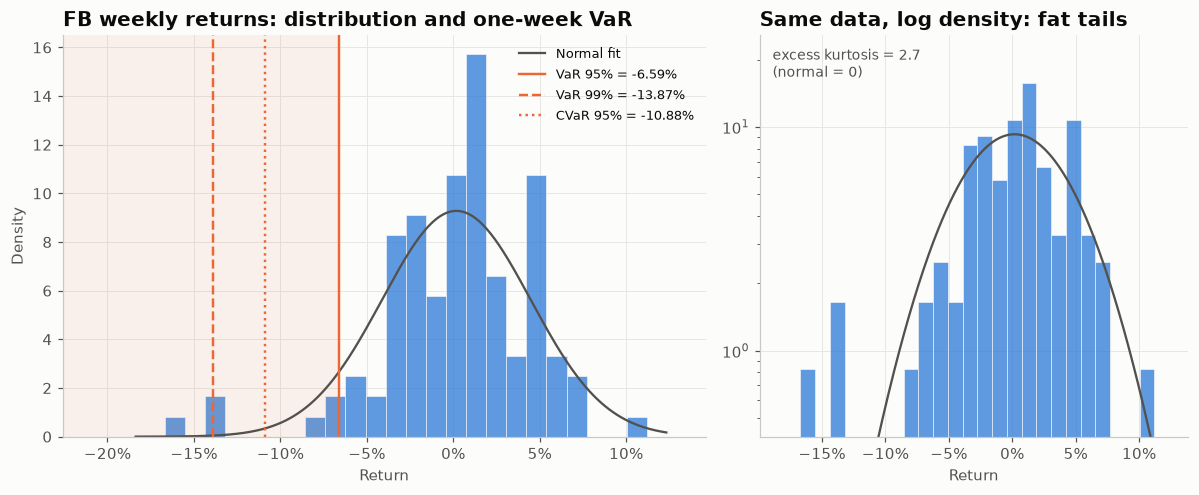

In [5]:
var95, var99 = np.quantile(r, [0.05, 0.01])
cvar95 = r[r <= var95].mean()
mu, sd = r.mean(), r.std()
xs = np.linspace(r.min() * 1.1, r.max() * 1.1, 400)
bins = np.linspace(r.min(), r.max(), 60 if len(r) > 500 else 25)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
for a in (ax, ax2):
    a.hist(r, bins=bins, density=True, color=PALETTE[0], alpha=0.75, edgecolor="#fcfcfb", linewidth=0.5)
    a.plot(xs, stats.norm.pdf(xs, mu, sd), color="#52514e", linewidth=1.5, label="Normal fit")
    a.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0 if r.abs().max() > 0.1 else 1))
for v, lab, style in [(var95, f"VaR 95% = {var95:.2%}", "-"), (var99, f"VaR 99% = {var99:.2%}", "--"),
                      (cvar95, f"CVaR 95% = {cvar95:.2%}", ":")]:
    ax.axvline(v, color=PALETTE[1], linewidth=1.6, linestyle=style, label=lab)
lo, hi = np.quantile(r, [0.002, 0.998])
ax.set_xlim(lo * 1.4, hi * 1.4)
ax.axvspan(lo * 1.4, var95, color=PALETTE[1], alpha=0.08, linewidth=0)
ax.set_title(f"{r.name}: distribution and {horizon} VaR")
ax.set_xlabel("Return")
ax.set_ylabel("Density")
ax.legend(loc="upper right", fontsize=8.5)
ax2.set_yscale("log")
ax2.set_ylim(bottom=0.5 / (len(r) * (bins[1] - bins[0])))
ax2.set_title("Same data, log density: fat tails")
ax2.set_xlabel("Return")
k = stats.kurtosis(r)
ax2.text(0.03, 0.97, f"excess kurtosis = {k:.1f}\n(normal = 0)", transform=ax2.transAxes, va="top",
         fontsize=9, color="#52514e")
fig.tight_layout()
plt.show()

---
Standalone script: [`return_distribution_var.py`](return_distribution_var.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)